In [3]:
import kagglehub
from pathlib import Path
import yaml
from collections import Counter
import matplotlib.pyplot as plt
from PIL import Image
import random
import matplotlib.patches as patches
import math
import shutil
from sklearn.model_selection import train_test_split
import hashlib
import torch
from google.colab import drive


In [4]:
!pip install -q kagglehub


## Vérification du GPU


In [5]:
import torch

print("PyTorch :", torch.__version__)
print("GPU disponible :", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU :", torch.cuda.get_device_name(0))

PyTorch : 2.11.0+cu130
GPU disponible : True
GPU : Tesla T4


## Téléchargement du dataset

In [6]:
dataset_path = kagglehub.dataset_download(
    "ashfakyeafi/road-vehicle-images-dataset"
)

Using Colab cache for faster access to the 'road-vehicle-images-dataset' dataset.


In [7]:
# print("Dataset téléchargé dans :", dataset_path)

## Exploration du dataset

### Structure des dossiers

In [8]:
dataset_path = Path(dataset_path)

for item in dataset_path.iterdir():
    print("📁" if item.is_dir() else "📄", item.name)

📁 trafic_data


### Exploration du dossier principal

In [9]:
traffic_path = dataset_path / "trafic_data"

for item in traffic_path.iterdir() :
  print("📁" if item.is_dir() else "📄", item.name)

📁 valid
📁 train
📄 data_1.yaml


### Structure des données Train et Valid

In [10]:
for folder in ["train", "valid"]:
    folder_path = traffic_path / folder

    print(f"\n📁 {folder}")

    for item in folder_path.iterdir():
        print("  📁" if item.is_dir() else "  📄", item.name)


📁 train
  📁 labels
  📄 labels.cache
  📁 images

📁 valid
  📁 labels
  📄 labels.cache
  📁 images


### Comptage des images et annotations

In [11]:
for folder in ["train","valid"]:
  images_path = traffic_path / folder / "images"
  labels_path = traffic_path / folder / "labels"

  images = [
      img for img in images_path.iterdir()
      if img.suffix.lower() in [".jpg", ".jpeg", ".png"]
  ]

  labels = list(labels_path.glob(".txt"))

  print(f"\n{folder.upper()}")
  print("Images :", len(images))
  print("Annotations :", len(labels))



TRAIN
Images : 2704
Annotations : 0

VALID
Images : 300
Annotations : 0


In [12]:
for folder in ["train", "valid"]:
    labels_path = traffic_path / folder / "labels"

    files = list(labels_path.iterdir())

    print(f"\n{folder.upper()}")
    print("Nombre d'éléments :", len(files))
    print("Exemples :", [f.name for f in files[:3]])


TRAIN
Nombre d'éléments : 2704
Exemples : ['Dipto_429_jpg.rf.41052bcdafb61f4810afcbcbb807ab4b.txt', 'Dipto_-109_jpg.rf.e2a6e8c452ee7f7d0413265a36f0c516.txt', 'Pias--445-_jpg.rf.d48e095b2403a4f60b386124832e0157.txt']

VALID
Nombre d'éléments : 300
Exemples : ['Pias--299-_jpg.rf.d99789045f9e78094450214f892c5224.txt', 'Pias--350-_jpg.rf.66e704ee7974871a7e7a9b9767b648cc.txt', 'Pias--366-_jpg.rf.67e15b0ae10be95e51aba283b94d074a.txt']


In [13]:
labels_path = traffic_path / "train" / "labels"

label_file = next(labels_path.glob("*.txt"))

print("Fichier :", label_file.name)
print("\nContenu :")
print(label_file.read_text())

Fichier : Dipto_429_jpg.rf.41052bcdafb61f4810afcbcbb807ab4b.txt

Contenu :
4 0.7921875 0.49722222222222223 0.3953125 0.9916666666666667
4 0.5375 0.475 0.05 0.10833333333333334
7 0.3234375 0.575 0.1265625 0.25
11 0.4625 0.4638888888888889 0.0234375 0.05277777777777778
18 0.5734375 0.45555555555555555 0.015625 0.027777777777777776


### Identification des classes

In [14]:
yaml_path = traffic_path / "data_1.yaml"

with open(yaml_path, "r") as file :
  config = yaml.safe_load(file)

print(config)

{'train': '../train/images', 'val': '../valid/images', 'nc': 21, 'names': ['ambulance', 'army vehicle', 'auto rickshaw', 'bicycle', 'bus', 'car', 'garbagevan', 'human hauler', 'minibus', 'minivan', 'motorbike', 'pickup', 'policecar', 'rickshaw', 'scooter', 'suv', 'taxi', 'three wheelers -CNG-', 'truck', 'van', 'wheelbarrow']}


### Vérification des classes

In [15]:
class_names = config["names"]
num_classes = config["nc"]

print("Nombre de classes déclaré :", num_classes)
print("Nombre de classes trouvé :", len(class_names))

for class_id, class_name in enumerate(class_names):
    print(f"{class_id}: {class_name}")

assert num_classes == len(class_names), "Incohérence dans les classes !"

Nombre de classes déclaré : 21
Nombre de classes trouvé : 21
0: ambulance
1: army vehicle
2: auto rickshaw
3: bicycle
4: bus
5: car
6: garbagevan
7: human hauler
8: minibus
9: minivan
10: motorbike
11: pickup
12: policecar
13: rickshaw
14: scooter
15: suv
16: taxi
17: three wheelers -CNG-
18: truck
19: van
20: wheelbarrow


## EDA

### Distribution des classes

In [16]:
class_counts = Counter()

labels_path = traffic_path / "train" / "labels"

for label_file in labels_path.glob("*.txt") :
  with open(label_file,"r") as file :
    for line in file :
      if line.strip():
        class_id = int(line.split()[0])
        class_counts[class_id] += 1

for class_id , count in sorted(class_counts.items()):
    print(f"{class_names[class_id]} : {count}")

ambulance : 70
army vehicle : 43
auto rickshaw : 372
bicycle : 427
bus : 2909
car : 4632
garbagevan : 3
human hauler : 169
minibus : 93
minivan : 822
motorbike : 1949
pickup : 1083
policecar : 31
rickshaw : 3336
scooter : 37
suv : 798
taxi : 41
three wheelers -CNG- : 2734
truck : 1411
van : 693
wheelbarrow : 111


### Visualisation des images

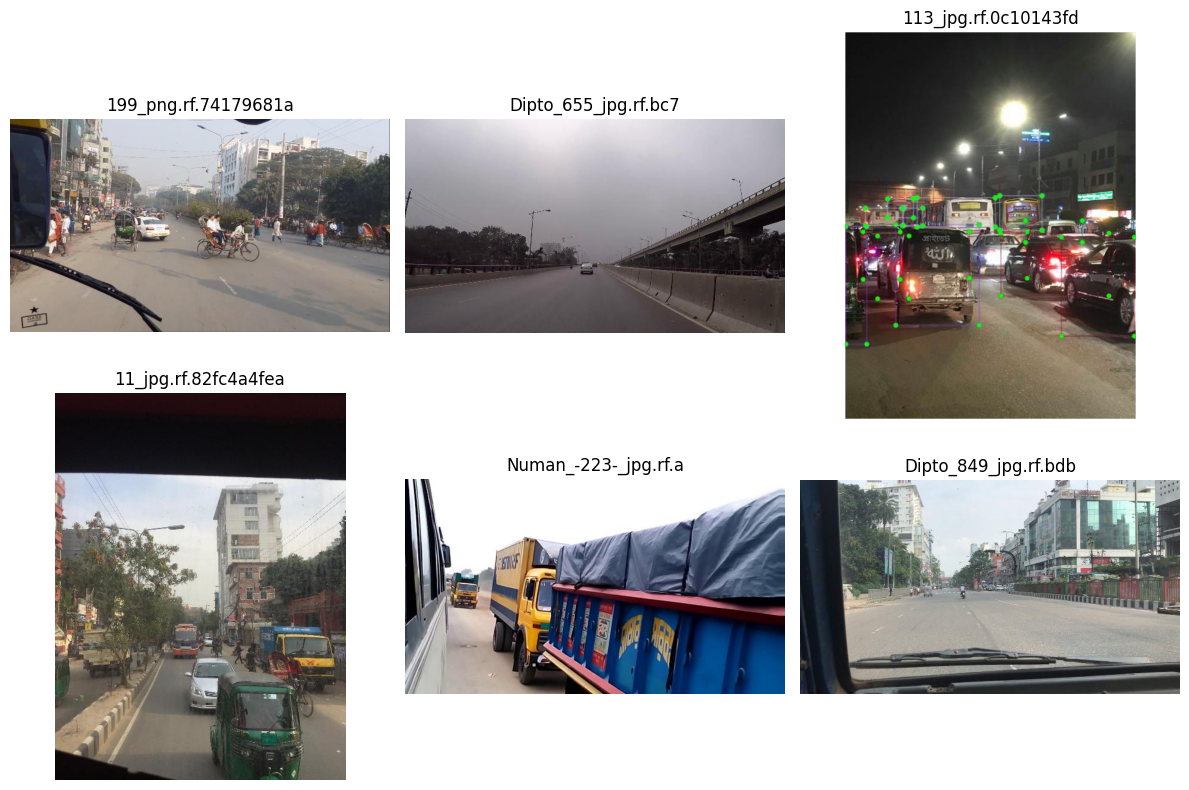

In [17]:
images_path = traffic_path / "train" / "images"

images = [
    img for img in images_path.iterdir()
    if img.suffix.lower() in [".jpg", ".jpeg", ".png"]
]

sample_images = random.sample(images,6)

fig , axes = plt.subplots(2,3,figsize=(12, 8))

for ax , img_path in zip(axes.flat , sample_images):
  with Image.open(img_path) as img :
    ax.imshow(img)

    ax.set_title(img_path.name[:20])
    ax.axis("off")

plt.tight_layout()
plt.show()

### Visualisation des Bounding Boxes

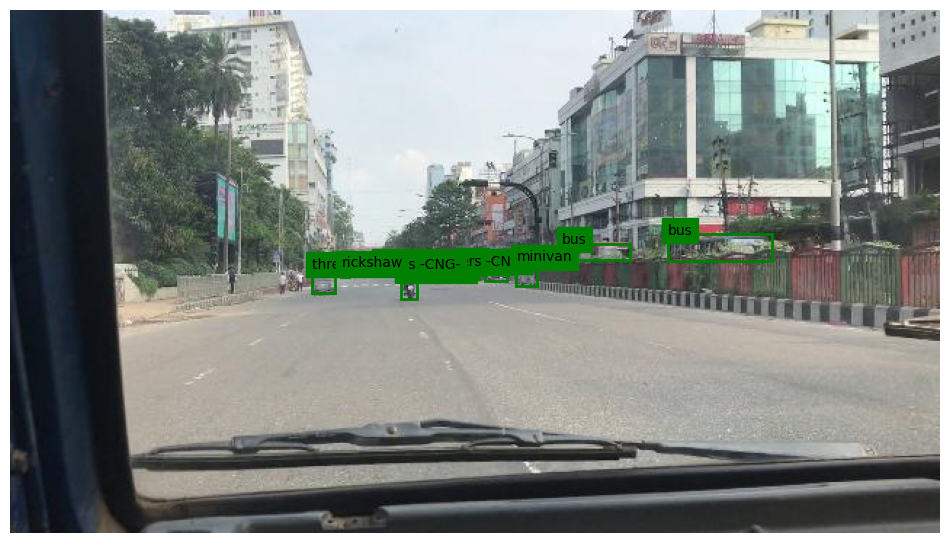

In [18]:
img_path = sample_images[5]

label_path = traffic_path / "train" / "labels" / f"{img_path.stem}.txt"

with Image.open(img_path) as img :
  fig, ax = plt.subplots(figsize=(12,8))
  ax.imshow(img)

  img_width, img_height = img.size

  with open(label_path,"r") as file :
    for line in file :
      class_id , x ,y , w ,h = map(float,line.split())

      x_min = (x - w / 2) * img_width
      y_min = (y - h / 2) * img_height

      box_width = w * img_width
      box_height = h * img_height

      rect = patches.Rectangle(
          (x_min,y_min),
          box_width,
          box_height,
          linewidth = 2,
          edgecolor = "green",
          facecolor = "none"
      )

      ax.add_patch(rect)
      ax.text(
          x_min, y_min,
          class_names[int(class_id)],
          color="black",
          fontsize=10,
          backgroundcolor="green"
      )

    ax.axis("off")
    plt.show()


### Vérification de l'intégrité des images

In [19]:
corrupted_images = []

for folder in ["train" , "valid"] :
  images_path = traffic_path / folder / "images"

  for img_path in images_path.iterdir() :
    if img_path.suffix.lower() in [".jpg", ".jpeg", ".png"]:
      try:
        with Image.open(img_path) as img :
          img.load()
      except Exception as e :
        corrupted_images.append(img_path)
        print(f"Image corrompue : {img_path.name} | {e}")

print("Nombre d'images corrompues :", len(corrupted_images))

Nombre d'images corrompues : 0


### Vérification de la correspondance images/annotations

In [20]:
for folder in ["train", "valid"]:
    images_path = traffic_path / folder / "images"
    labels_path = traffic_path / folder / "labels"

    print(f"\n{folder.upper()}")

    print("Images :", len(list(images_path.iterdir())))
    print("Labels avec glob :", len(list(labels_path.glob("*.txt"))))
    print("Labels avec rglob :", len(list(labels_path.rglob("*.txt"))))
    print("Tous les fichiers labels :", len(list(labels_path.iterdir())))


TRAIN
Images : 2704
Labels avec glob : 2704
Labels avec rglob : 2704
Tous les fichiers labels : 2704

VALID
Images : 300
Labels avec glob : 300
Labels avec rglob : 300
Tous les fichiers labels : 300


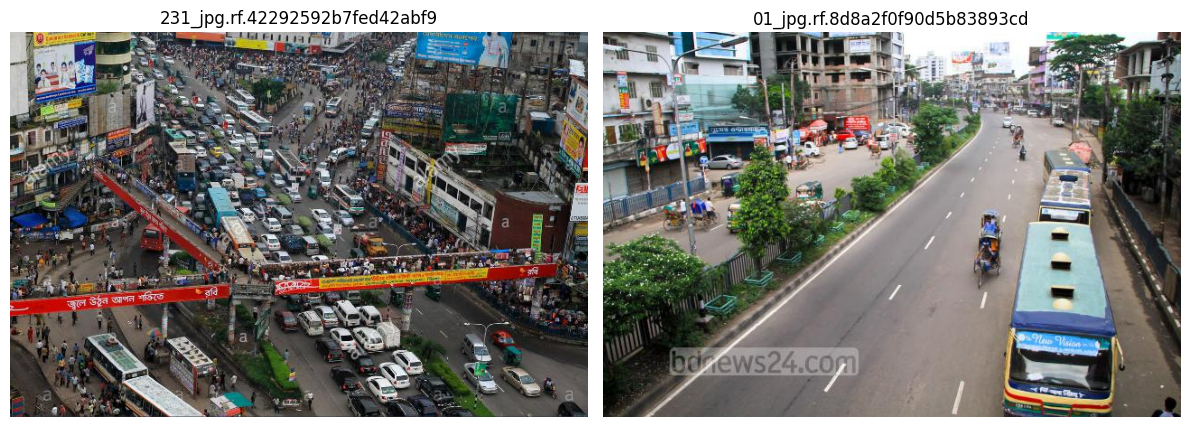

In [21]:
images_path = traffic_path / "train" / "images"
labels_path = traffic_path / "train" / "labels"

empty_labels = [
    label for label in labels_path.glob("*.txt")
    if not label.read_text().strip()
]

fig, axes = plt.subplots(1, len(empty_labels), figsize=(12, 5))

for ax, label_path in zip(axes, empty_labels):

    image_path = next(
        img for img in images_path.iterdir()
        if img.stem == label_path.stem
    )

    with Image.open(image_path) as img:
        ax.imshow(img.convert("RGB"))

    ax.set_title(image_path.name[:30])
    ax.axis("off")

plt.tight_layout()
plt.show()

### Vérification de la validité des annotations YOLO

In [22]:
invalid_annotations = []

for folder in ["train", "valid"]:
    labels_path = traffic_path / folder / "labels"

    for label_file in labels_path.glob("*.txt"):

        with open(label_file, "r") as file:

            for line_number, line in enumerate(file, start=1):
                values = line.split()

                if len(values) != 5:
                    invalid_annotations.append((label_file.name, line_number))
                    continue

                try:
                    class_id = int(values[0])
                    x, y, w, h = map(float, values[1:])

                    valid = (
                        0 <= class_id < num_classes
                        and all(math.isfinite(v) for v in [x, y, w, h])
                        and 0 <= x <= 1
                        and 0 <= y <= 1
                        and 0 < w <= 1
                        and 0 < h <= 1
                        and x - w / 2 >= 0
                        and x + w / 2 <= 1
                        and y - h / 2 >= 0
                        and y + h / 2 <= 1
                    )

                    if not valid:
                        invalid_annotations.append((label_file.name, line_number))

                except ValueError:
                    invalid_annotations.append((label_file.name, line_number))

print("Nombre d'annotations invalides :", len(invalid_annotations))
print("Exemples :", invalid_annotations[:5])

Nombre d'annotations invalides : 24
Exemples : [('Pias--359-_PNG.rf.43bcf36efe5cf8c37552d2c45fffea60.txt', 1), ('Pias--359-_PNG.rf.43bcf36efe5cf8c37552d2c45fffea60.txt', 2), ('Pias--359-_PNG.rf.43bcf36efe5cf8c37552d2c45fffea60.txt', 3), ('Pias--359-_PNG.rf.43bcf36efe5cf8c37552d2c45fffea60.txt', 4), ('Pias--359-_PNG.rf.43bcf36efe5cf8c37552d2c45fffea60.txt', 5)]


### Analyse des annotations invalides

In [23]:
file_name, line_number = invalid_annotations[0]

for folder in ["train", "valid"]:
    label_path = traffic_path / folder / "labels" / file_name

    if label_path.exists():
        lines = label_path.read_text().splitlines()

        print("Dossier :", folder)
        print("Fichier :", file_name)
        print("Ligne :", line_number)
        print("Annotation :", lines[line_number - 1])
        break

Dossier : valid
Fichier : Pias--359-_PNG.rf.43bcf36efe5cf8c37552d2c45fffea60.txt
Ligne : 1
Annotation : 9 0 0 0 0


#### Identification des anomalies dans les annotations

In [24]:
for file_name, line_number in invalid_annotations:
    for folder in ["train", "valid"]:
        label_path = traffic_path / folder / "labels" / file_name

        if label_path.exists():
            lines = label_path.read_text().splitlines()

            print(
                folder,
                "|", file_name,
                "| Ligne", line_number,
                "|", lines[line_number - 1]
            )
            break

valid | Pias--359-_PNG.rf.43bcf36efe5cf8c37552d2c45fffea60.txt | Ligne 1 | 9 0 0 0 0
valid | Pias--359-_PNG.rf.43bcf36efe5cf8c37552d2c45fffea60.txt | Ligne 2 | 15 0 0 0 0
valid | Pias--359-_PNG.rf.43bcf36efe5cf8c37552d2c45fffea60.txt | Ligne 3 | 13 0 0 0 0
valid | Pias--359-_PNG.rf.43bcf36efe5cf8c37552d2c45fffea60.txt | Ligne 4 | 13 0 0 0 0
valid | Pias--359-_PNG.rf.43bcf36efe5cf8c37552d2c45fffea60.txt | Ligne 5 | 13 0 0 0 0
valid | Pias--359-_PNG.rf.43bcf36efe5cf8c37552d2c45fffea60.txt | Ligne 6 | 13 0 0 0 0
valid | Pias--359-_PNG.rf.43bcf36efe5cf8c37552d2c45fffea60.txt | Ligne 7 | 13 0 0 0 0
valid | Pias--359-_PNG.rf.43bcf36efe5cf8c37552d2c45fffea60.txt | Ligne 8 | 13 0 0 0 0
valid | Pias--359-_PNG.rf.43bcf36efe5cf8c37552d2c45fffea60.txt | Ligne 9 | 13 0 0 0 0
valid | Pias--359-_PNG.rf.43bcf36efe5cf8c37552d2c45fffea60.txt | Ligne 10 | 13 0 0 0 0
valid | Pias--359-_PNG.rf.43bcf36efe5cf8c37552d2c45fffea60.txt | Ligne 11 | 17 0 0 0 0
valid | Pias--359-_PNG.rf.43bcf36efe5cf8c37552d2c45ff

### Visualisation des images avec annotations invalides

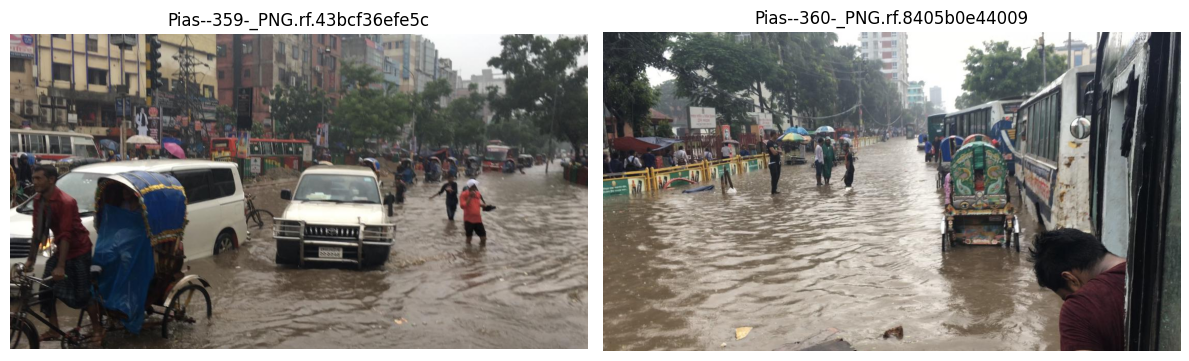

In [25]:
images_path = traffic_path / "valid" / "images"

invalid_files = sorted(set(
    file_name for file_name, line_number in invalid_annotations
))

fig, axes = plt.subplots(1, len(invalid_files), figsize=(12, 5))

for ax, file_name in zip(axes, invalid_files):

    image_path = next(
        img for img in images_path.iterdir()
        if img.stem == Path(file_name).stem
    )

    with Image.open(image_path) as img:
        ax.imshow(img.convert("RGB"))

    ax.set_title(image_path.name[:30])
    ax.axis("off")

plt.tight_layout()
plt.show()

### Nettoyage du dataset


#### Création d'une copie de travail

In [26]:
clean_path = Path("/content/traffic_clean")

shutil.copytree(
    traffic_path,
    clean_path,
    dirs_exist_ok=True
)

print("Copie créée :", clean_path)

for folder in ["train", "valid"]:
    images = list((clean_path / folder / "images").iterdir())
    labels = list((clean_path / folder / "labels").glob("*.txt"))

    print(f"{folder.upper()} : {len(images)} images, {len(labels)} labels")

Copie créée : /content/traffic_clean
TRAIN : 2704 images, 2704 labels
VALID : 300 images, 300 labels


### Suppression des images et annotations invalides

In [27]:
train_labels = clean_path / "train" / "labels"

empty_labels = [
    label.name
    for label in train_labels.glob("*.txt")
    if not label.read_text().strip()
]

# identifier les fichiers avec annotations invalides
invalid_files = {
    file_name
    for file_name, line_number in invalid_annotations
}


for folder, files in [
    ("train", empty_labels),
    ("valid", invalid_files)
]:
    images_path = clean_path / folder / "images"
    labels_path = clean_path / folder / "labels"

    for file_name in files:
        label_path = labels_path / file_name

        # supprimer l'image correspondante
        for image_path in images_path.glob(
            Path(file_name).stem + ".*"
        ):
            image_path.unlink()

        # supprimer son annotation
        if label_path.exists():
            label_path.unlink()

for folder in ["train", "valid"]:
    images = list((clean_path / folder / "images").iterdir())
    labels = list((clean_path / folder / "labels").glob("*.txt"))

    print(f"{folder.upper()} : {len(images)} images, {len(labels)} labels")

TRAIN : 2702 images, 2702 labels
VALID : 298 images, 298 labels


## Preprocessing

### Data Splitting — Création des ensembles Train, Validation et Test

In [28]:
train_images_path = clean_path / "train" / "images"
train_labels_path = clean_path / "train" / "labels"

test_images_path = clean_path / "test" / "images"
test_labels_path = clean_path / "test" / "labels"

#creation des dossier test d'aprés train
test_images_path.mkdir(parents=True, exist_ok=True)
test_labels_path.mkdir(parents=True, exist_ok=True)

images = sorted([
    img for img in train_images_path.iterdir()
    if img.suffix.lower() in [".jpg", ".jpeg", ".png"]
])

train_images, test_images = train_test_split(
    images,
    test_size= 0.2,
    random_state= 42
)

for img_path in test_images:

    label_path = train_labels_path / (img_path.stem + ".txt")

    shutil.move(
        str(img_path),
        str(test_images_path / img_path.name)
    )

    shutil.move(
        str(label_path),
        str(test_labels_path / label_path.name)
    )

# verification d'effectif
for folder in ["train", "valid", "test"]:

    images_path = clean_path / folder / "images"
    labels_path = clean_path / folder / "labels"

    n_images = len([
        img for img in images_path.iterdir()
        if img.suffix.lower() in [".jpg", ".jpeg", ".png"]
    ])

    n_labels = len(list(labels_path.glob("*.txt")))

    print(f"{folder.upper()} : {n_images} images, {n_labels} labels")

TRAIN : 2161 images, 2161 labels
VALID : 298 images, 298 labels
TEST : 541 images, 541 labels


### Vérification des doublons entre Train, Validation et Test

In [29]:
def image_hashes(folder):
    hashes = set()

    for img_path in (clean_path / folder / "images").iterdir():
        if img_path.suffix.lower() in [".jpg", ".jpeg", ".png"]:
            file_hash = hashlib.sha256(img_path.read_bytes()).hexdigest()
            hashes.add(file_hash)

    return hashes

train_hashes = image_hashes("train")
valid_hashes = image_hashes("valid")
test_hashes = image_hashes("test")

print("Train / Valid :", len(train_hashes & valid_hashes))
print("Train / Test :", len(train_hashes & test_hashes))
print("Valid / Test :", len(valid_hashes & test_hashes))

Train / Valid : 0
Train / Test : 0
Valid / Test : 0


###  Configuration du fichier data.yaml pour YOLOv9-C

In [30]:
import yaml

data_config = {
    "train": str(clean_path / "train" / "images"),
    "val": str(clean_path / "valid" / "images"),
    "test": str(clean_path / "test" / "images"),
    "nc": num_classes,
    "names": class_names
}

yaml_path = clean_path / "data.yaml"

with open(yaml_path, "w") as file:
    yaml.safe_dump(
        data_config,
        file,
        sort_keys=False,
        allow_unicode=True
    )

print("Fichier créé :", yaml_path)

with open(yaml_path, "r") as file:
    print(file.read())

Fichier créé : /content/traffic_clean/data.yaml
train: /content/traffic_clean/train/images
val: /content/traffic_clean/valid/images
test: /content/traffic_clean/test/images
nc: 21
names:
- ambulance
- army vehicle
- auto rickshaw
- bicycle
- bus
- car
- garbagevan
- human hauler
- minibus
- minivan
- motorbike
- pickup
- policecar
- rickshaw
- scooter
- suv
- taxi
- three wheelers -CNG-
- truck
- van
- wheelbarrow



## Installation et configuration de YOLOv9-C

### Clonage du dépôt officiel YOLOv9

In [31]:
%cd /content

!git clone https://github.com/WongKinYiu/yolov9.git

%cd /content/yolov9

!git status --short

/content
fatal: destination path 'yolov9' already exists and is not an empty directory.
/content/yolov9
 M train_dual.py
?? __pycache__/
?? models/__pycache__/
?? utils/__pycache__/
?? utils/loggers/__pycache__/
?? utils/loggers/clearml/__pycache__/
?? utils/loggers/comet/__pycache__/
?? utils/loggers/wandb/__pycache__/
?? utils/segment/__pycache__/
?? utils/tal/__pycache__/
?? yolov9-c.pt


### Installation des dépendances YOLOv9

In [32]:
%cd /content/yolov9

!pip install -r requirements.txt

/content/yolov9


### Vérification de la disponibilité du GPU

In [33]:
print("Version PyTorch :", torch.__version__)
print("CUDA disponible :", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU :", torch.cuda.get_device_name(0))
    print("Version CUDA de PyTorch :", torch.version.cuda)
else:
    print("GPU non disponible pour PyTorch")

Version PyTorch : 2.11.0+cu130
CUDA disponible : True
GPU : Tesla T4
Version CUDA de PyTorch : 13.0


### Vérification du GPU NVIDIA

In [34]:
!nvidia-smi

Thu Nov  5 21:57:47 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   42C    P8              9W /   70W |       3MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

### Vérification des fichiers après activation du GPU

In [35]:
clean_path = Path("/content/traffic_clean")
yolo_path = Path("/content/yolov9")

print("Dataset disponible :", clean_path.exists())
print("YOLOv9 disponible :", yolo_path.exists())
print("data.yaml disponible :", (clean_path / "data.yaml").exists())

for folder in ["train", "valid", "test"]:
    images_path = clean_path / folder / "images"
    labels_path = clean_path / folder / "labels"

    if images_path.exists() and labels_path.exists():
        print(
            f"{folder.upper()} : "
            f"{len(list(images_path.iterdir()))} images, "
            f"{len(list(labels_path.glob('*.txt')))} labels"
        )
    else:
        print(f"{folder.upper()} : dossier introuvable")

Dataset disponible : True
YOLOv9 disponible : True
data.yaml disponible : True
TRAIN : 2161 images, 2161 labels
VALID : 298 images, 298 labels
TEST : 541 images, 541 labels


### Téléchargement des poids préentraînés YOLOv9-C

In [36]:
%cd /content/yolov9

!wget -q --show-progress -O yolov9-c.pt \
https://github.com/WongKinYiu/yolov9/releases/download/v0.1/yolov9-c.pt


weights_path = Path("/content/yolov9/yolov9-c.pt")

print("Modèle téléchargé :", weights_path.exists())

if weights_path.exists():
    print("Taille :", round(weights_path.stat().st_size / (1024**2), 2), "Mo")

/content/yolov9
yolov9-c.pt         100%[===================>]  98.37M  66.4MB/s    in 1.5s    
Modèle téléchargé : True
Taille : 98.37 Mo


## Préparation de l'entraînement YOLOv9-C

### Vérification des fichiers nécessaires à l'entraînement

In [37]:
yolo_path = Path("/content/yolov9")
clean_path = Path("/content/traffic_clean")

files = {
    "Script d'entraînement": yolo_path / "train_dual.py",
    "Configuration du modèle": yolo_path / "models" / "detect" / "yolov9-c.yaml",
    "Poids préentraînés": yolo_path / "yolov9-c.pt",
    "Configuration du dataset": clean_path / "data.yaml"
}

for name, path in files.items():
    print(f"{name} : {path.exists()}")

with open(clean_path / "data.yaml", "r") as file:
    data = yaml.safe_load(file)

print("\nNombre de classes :", data["nc"])
print("Classes déclarées :", len(data["names"]))
print("Train :", data["train"])
print("Validation :", data["val"])
print("Test :", data["test"])

Script d'entraînement : True
Configuration du modèle : True
Poids préentraînés : True
Configuration du dataset : True

Nombre de classes : 21
Classes déclarées : 21
Train : /content/traffic_clean/train/images
Validation : /content/traffic_clean/valid/images
Test : /content/traffic_clean/test/images


### Entraînement du modèle YOLOv9-C avec Transfer Learning

#### Correction de la compatibilité PyTorch / YOLOv9

In [38]:
train_script = Path("/content/yolov9/train_dual.py")

code = train_script.read_text()

old = "torch.load(weights, map_location='cpu')"
new = "torch.load(weights, map_location='cpu', weights_only=False)"

if old in code:
    code = code.replace(old, new)
    train_script.write_text(code)
    print("Correction appliquée avec succès !")
elif new in code:
    print("Correction déjà appliquée.")
else:
    print("Instruction introuvable : vérifier le script.")

Correction déjà appliquée.


In [39]:
%cd /content/yolov9

!WANDB_MODE=disabled python train_dual.py \
    --workers 2 \
    --device 0 \
    --batch 4 \
    --img 640 \
    --epochs 1 \
    --data /content/traffic_clean/data.yaml \
    --cfg models/detect/yolov9-c.yaml \
    --weights /content/yolov9/yolov9-c.pt \
    --hyp hyp.scratch-high.yaml \
    --name roadvision_test \
    --project /content/runs/train

/content/yolov9
/content/yolov9/utils/general.py:29: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources as pkg
I0000 00:00:1793911858.302537    1836 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1793911860.611777    1836 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
train_dual: weights=/content/yolov9/yolov9-c.pt, cfg=models/detect/yolov9-c.yaml, data=/content/traffic_clean/data.yaml, hyp=hyp.scratch-high.yaml, epochs=1, batch_size=4, imgsz=640, rect=False, resume=False, nosave=False, noval=False, noautoanchor

In [40]:
from pathlib import Path

weights_dir = Path("/content/runs/train/roadvision_test/weights")

for name in ["best.pt", "last.pt"]:
    path = weights_dir / name
    print(name, ":", path.exists())

best.pt : False
last.pt : False


### Sauvegarde des checkpoints sur Google Drive

In [41]:
drive.mount("/content/drive")

source = Path("/content/runs/train/roadvision_test/weights")
destination = Path("/content/drive/MyDrive/RoadVision_AI/weights")

destination.mkdir(parents=True, exist_ok=True)

for name in ["best.pt", "last.pt"]:
    shutil.copy2(source / name, destination / name)

    print(
        name,
        "sauvegardé :",
        (destination / name).exists()
    )

MessageError: Error: credential propagation was unsuccessful

### l'entraînement à partir du checkpoint

In [ ]:
run_path = Path("/content/runs/train/roadvision_test")
opt_path = run_path / "opt.yaml"

print("Configuration disponible :", opt_path.exists())

if opt_path.exists():
    with open(opt_path, "r") as file:
        opt = yaml.safe_load(file)

    opt["epochs"] = 5

    with open(opt_path, "w") as file:
        yaml.safe_dump(opt, file, sort_keys=False)

    print("Nombre total d'epochs :", opt["epochs"])

In [ ]:
%cd /content/yolov9

!WANDB_MODE=disabled python train_dual.py \
    --resume /content/runs/train/roadvision_test/weights/last.pt